In [1322]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data splitting and preprocessing
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Save model
import joblib

# Other
import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully")

Libraries imported successfully


In [1323]:
df=pd.read_csv('C:\Data science\practice_1\Diabetes\Data\diabetes_prediction_dataset.csv')

## Understand the data

In [1324]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [1325]:
df.tail()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0
99999,Female,57.0,0,0,current,22.43,6.6,90,0


In [1326]:
df.sample(5,random_state=42)

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
75721,Female,13.0,0,0,No Info,20.82,5.8,126,0
80184,Female,3.0,0,0,No Info,21.00,5.0,145,0
19864,Male,63.0,0,0,former,25.32,3.5,200,0
76699,Female,2.0,0,0,never,17.43,6.1,126,0
92991,Female,33.0,0,0,not current,40.08,6.2,200,1


In [1327]:
df.columns.to_list()

['gender',
 'age',
 'hypertension',
 'heart_disease',
 'smoking_history',
 'bmi',
 'HbA1c_level',
 'blood_glucose_level',
 'diabetes']

In [1328]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 6.9 MB


In [1329]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,100000.0,41.885856,22.516840,0.08,24.00,43.00,60.00,80.00
hypertension,100000.0,0.074850,0.263150,0.00,0.00,0.00,0.00,1.00
heart_disease,100000.0,0.039420,0.194593,0.00,0.00,0.00,0.00,1.00
bmi,100000.0,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,5.527507,1.070672,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,100000.0,138.058060,40.708136,80.00,100.00,140.00,159.00,300.00
diabetes,100000.0,0.085000,0.278883,0.00,0.00,0.00,0.00,1.00


In [1330]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [1331]:
df.duplicated().sum()

np.int64(3854)

In [1332]:
df.nunique()

gender                    3
age                     102
hypertension              2
heart_disease             2
smoking_history           6
bmi                    4247
HbA1c_level              18
blood_glucose_level      18
diabetes                  2
dtype: int64

In [1333]:
df['diabetes'].value_counts()

diabetes
0    91500
1     8500
Name: count, dtype: int64

In [1334]:
df['diabetes'].value_counts(normalize=True)*100

diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64

## Data cleaning

In [1335]:
# Check target values
print(df["diabetes"].value_counts(dropna=False))

diabetes
0    91500
1     8500
Name: count, dtype: int64


In [1336]:
df.dtypes

gender                     str
age                    float64
hypertension             int64
heart_disease            int64
smoking_history            str
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

In [1337]:
df.duplicated().sum()

np.int64(3854)

In [1338]:
display(df[df.duplicated(keep=False)].tail(20))

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
99795,Male,46.0,0,0,No Info,27.32,3.5,140,0
99804,Female,66.0,0,0,No Info,27.32,5.7,90,0
99806,Female,45.0,0,0,No Info,27.32,6.6,130,0
99811,Female,48.0,0,0,No Info,27.32,6.0,85,0
99836,Male,3.0,0,0,No Info,27.32,5.0,85,0
99856,Male,3.0,0,0,No Info,27.32,6.6,130,0
99860,Male,23.0,0,0,No Info,27.32,6.2,85,0
99875,Female,27.0,0,0,never,27.32,6.6,160,0
99894,Male,80.0,0,0,No Info,27.32,6.1,80,0
99912,Male,80.0,0,1,former,27.32,5.0,140,0


In [1339]:
# Count repeated complete rows
display(
    df.value_counts()
    .reset_index(name="Count")
    .query("Count > 1")
    .head(20)
)

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,Count
0,Female,80.0,0,0,No Info,27.32,6.5,159,0,9
1,Female,80.0,0,0,No Info,27.32,6.2,90,0,9
2,Female,80.0,0,0,No Info,27.32,4.0,85,0,8
3,Female,80.0,0,0,No Info,27.32,4.0,160,0,7
4,Female,80.0,0,0,No Info,27.32,4.0,158,0,7
5,Female,80.0,0,0,No Info,27.32,4.5,140,0,7
6,Female,80.0,0,0,No Info,27.32,4.0,126,0,7
7,Female,80.0,0,0,No Info,27.32,6.6,155,0,7
8,Female,80.0,0,0,No Info,27.32,4.8,80,0,6
9,Male,80.0,0,0,No Info,27.32,6.0,100,0,6


In [1340]:
print(df.shape)

(100000, 9)


In [1341]:
# Check duplicate feature combinations with different target values

duplicate_features = df[
    df.duplicated(
        subset=df.columns.drop("diabetes"),
        keep=False
    )
]

display(duplicate_features.head(20))

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
10,Female,53.0,0,0,never,27.32,6.1,85,0
14,Female,76.0,0,0,No Info,27.32,5.0,160,0
18,Female,42.0,0,0,No Info,27.32,5.7,80,0
41,Male,5.0,0,0,No Info,27.32,6.6,130,0
44,Female,67.0,0,0,No Info,27.32,3.5,160,0
51,Female,26.0,0,0,No Info,27.32,4.0,200,0
56,Male,30.0,0,0,No Info,27.32,6.6,140,0
62,Female,30.0,0,0,current,27.32,6.5,158,0
95,Male,19.0,0,0,never,27.32,6.1,80,0


In [1342]:
# Count how many feature combinations have conflicting target values

conflicting_records = (
    duplicate_features
    .groupby(list(df.columns.drop("diabetes")))["diabetes"]
    .nunique()
)

print(
    "Feature combinations with conflicting target values:",
    (conflicting_records > 1).sum()
)

Feature combinations with conflicting target values: 91


In [1343]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [1344]:
print("Gender values:")
print(df["gender"].value_counts(dropna=False))

print("\nSmoking History values:")
print(df["smoking_history"].value_counts(dropna=False))

print("\nDiabetes values:")
print(df["diabetes"].value_counts(dropna=False))

Gender values:
gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64

Smoking History values:
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64

Diabetes values:
diabetes
0    91500
1     8500
Name: count, dtype: int64


## EDA

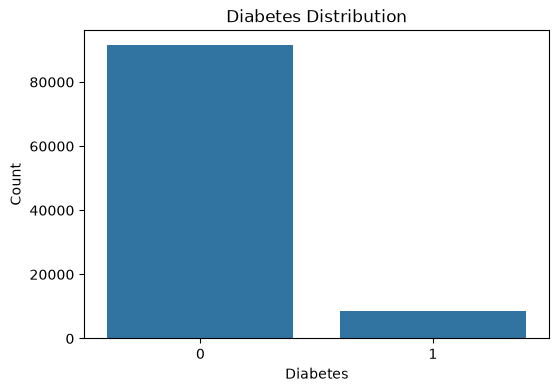

In [1345]:
#Target distribution
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="diabetes")

plt.title("Diabetes Distribution")
plt.xlabel("Diabetes")
plt.ylabel("Count")

plt.show()

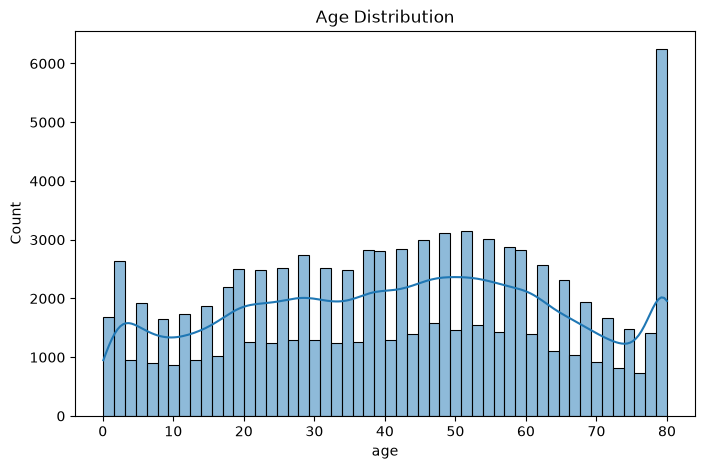

In [1346]:
#Age distribution
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", kde=True)

plt.title("Age Distribution")
plt.show()

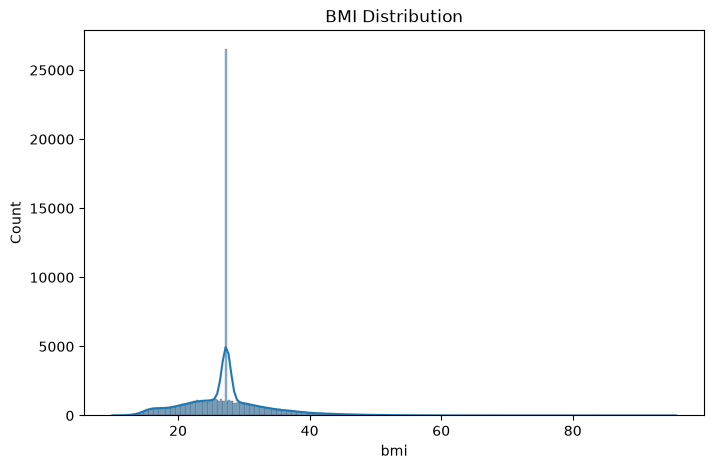

In [1347]:
#BMi distrribution
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="bmi", kde=True)

plt.title("BMI Distribution")
plt.show()

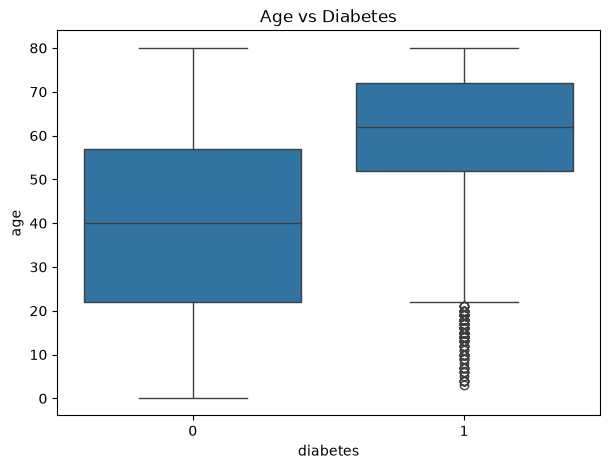

In [1348]:
#Age compared with diabetes
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="diabetes", y="age")

plt.title("Age vs Diabetes")
plt.show()

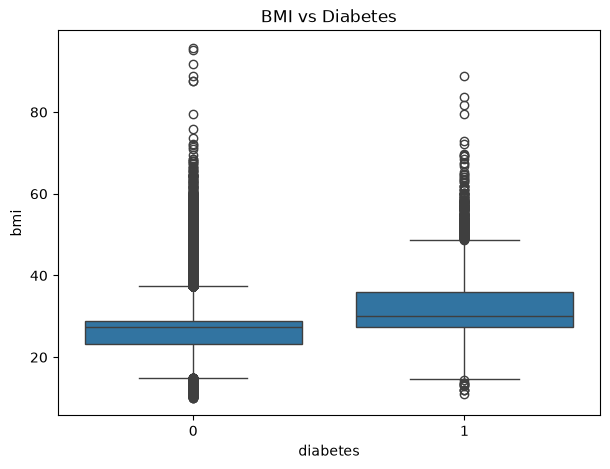

In [1349]:
#BMI compared with diabetes
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="diabetes", y="bmi")

plt.title("BMI vs Diabetes")
plt.show()

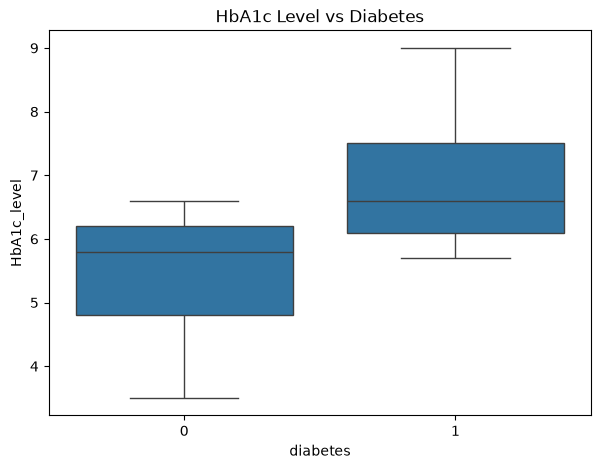

In [1350]:
# HbA1c level compared with diabetes
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="diabetes", y="HbA1c_level")

plt.title("HbA1c Level vs Diabetes")
plt.show()

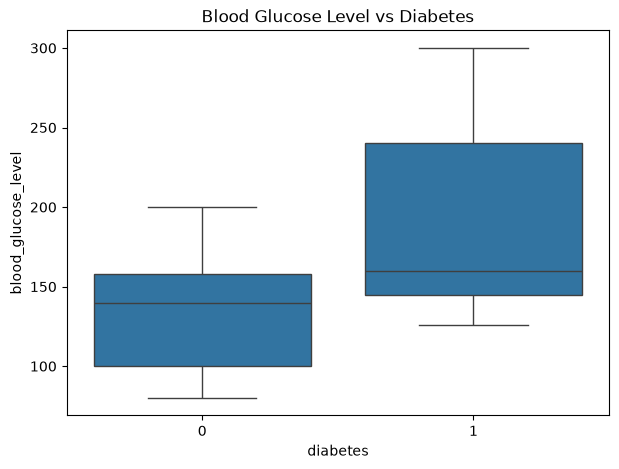

In [1351]:
#Blood glucose compared with diabetes
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="diabetes", y="blood_glucose_level")

plt.title("Blood Glucose Level vs Diabetes")
plt.show()

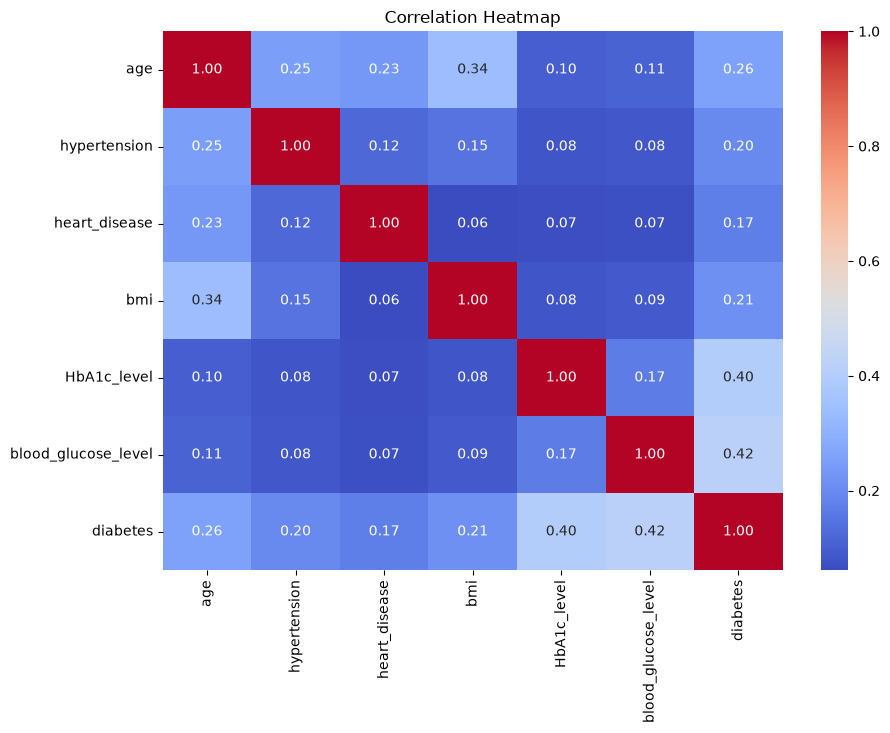

In [1352]:
#Correlation heatmap
plt.figure(figsize=(10, 7))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

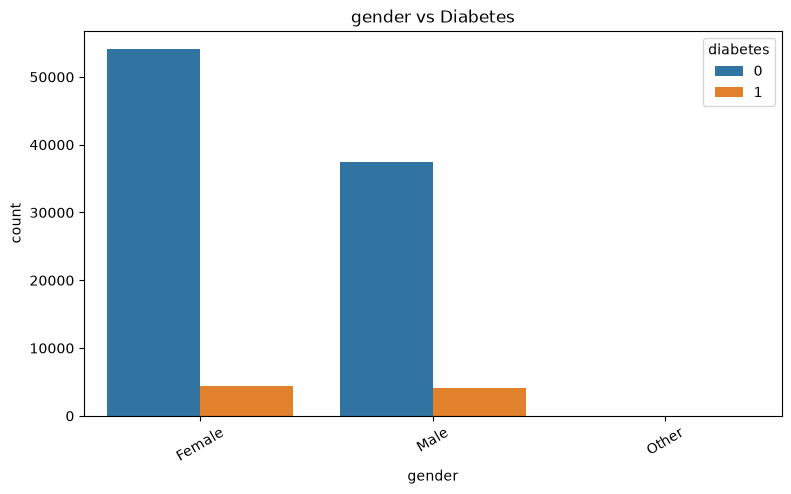

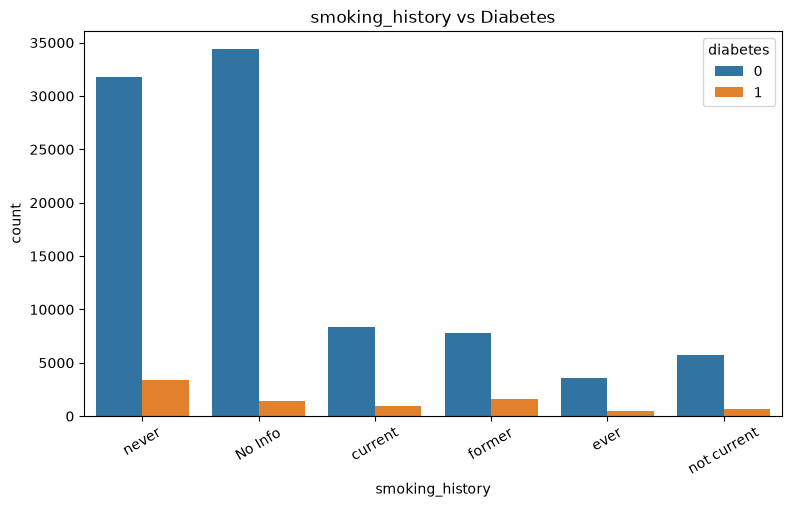

In [1353]:
#Categorical features compared with diabetes
categorical_columns = ["gender", "smoking_history"]

for column in categorical_columns:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x=column,
        hue="diabetes"
    )

    plt.title(f"{column} vs Diabetes")
    plt.xticks(rotation=30)
    plt.show()

## Outlier detection

In [1354]:
outlier_columns = [
    "age",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level"
]

In [1355]:
for column in outlier_columns:

    print(f"\nColumn: {column}")

    print("Minimum:", df[column].min())
    print("Maximum:", df[column].max())

    print("\nLowest 5 values:")
    print(df[column].nsmallest(5).tolist())

    print("\nHighest 5 values:")
    print(df[column].nlargest(5).tolist())


Column: age
Minimum: 0.08
Maximum: 80.0

Lowest 5 values:
[0.08, 0.08, 0.08, 0.08, 0.08]

Highest 5 values:
[80.0, 80.0, 80.0, 80.0, 80.0]

Column: bmi
Minimum: 10.01
Maximum: 95.69

Lowest 5 values:
[10.01, 10.01, 10.08, 10.14, 10.19]

Highest 5 values:
[95.69, 95.22, 91.82, 88.76, 88.72]

Column: HbA1c_level
Minimum: 3.5
Maximum: 9.0

Lowest 5 values:
[3.5, 3.5, 3.5, 3.5, 3.5]

Highest 5 values:
[9.0, 9.0, 9.0, 9.0, 9.0]

Column: blood_glucose_level
Minimum: 80
Maximum: 300

Lowest 5 values:
[80, 80, 80, 80, 80]

Highest 5 values:
[300, 300, 300, 300, 300]


In [1356]:
outlier_results = []

for column in outlier_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        "Column": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)

,Column,Lower Bound,Upper Bound,Outlier Count
0,age,-30.000,114.000,0
1,bmi,14.705,38.505,7086
2,HbA1c_level,2.700,8.300,1315
3,blood_glucose_level,11.500,247.500,2038


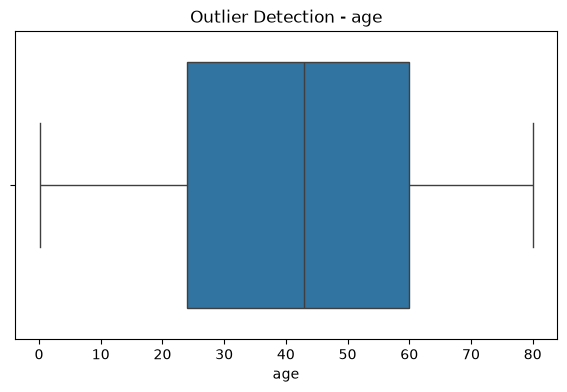

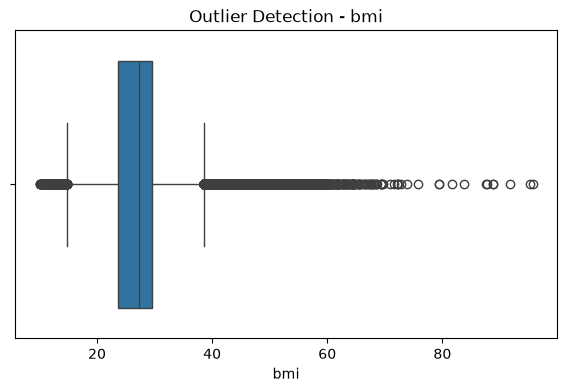

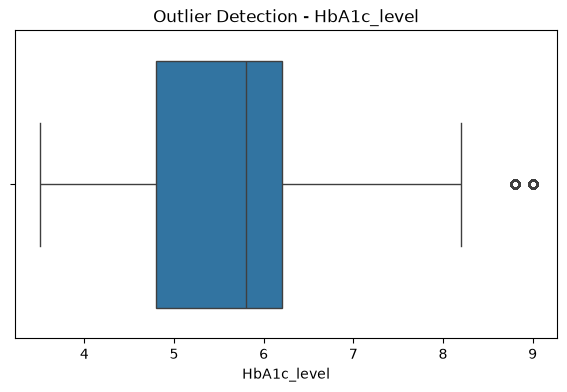

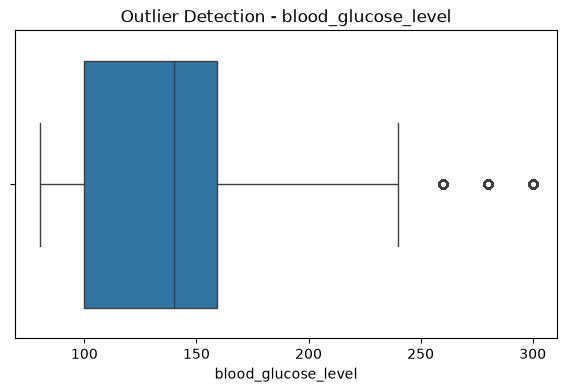

In [1357]:
for column in outlier_columns:

    plt.figure(figsize=(7, 4))

    sns.boxplot(x=df[column])

    plt.title(f"Outlier Detection - {column}")

    plt.show()

## Feature Selection and Target Separation

In [1358]:
# Features
X = df.drop("diabetes", axis=1)

# Target
y = df["diabetes"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

Features Shape: (100000, 8)
Target Shape: (100000,)

Feature Columns:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level']


In [1359]:
#Define numerical and categorical columns.
numeric_features = [
    "age",
    "hypertension",
    "heart_disease",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level"
]

categorical_features = [
    "gender",
    "smoking_history"
]

In [1360]:
#Check that all feature columns are accounted for.
selected_features = numeric_features + categorical_features

print("Missing from feature lists:",
      set(X.columns) - set(selected_features))

print("Unexpected feature names:",
      set(selected_features) - set(X.columns))

Missing from feature lists: set()
Unexpected feature names: set()


## Train test split

In [1361]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Features: (80000, 8)
Testing Features: (20000, 8)

Training Target Distribution:
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64

Testing Target Distribution:
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64


In [1362]:
# Why stratify=y? The diabetes dataset has an imbalanced target. 
# Stratification helps maintain approximately the same class proportions in both training and testing sets.

# The test set must remain untouched until final evaluation.

## Data preprocessing

In [1363]:
# Numerical preprocessing
numeric_preprocessing = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])

# Categorical preprocessing
categorical_preprocessing = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))])

In [1364]:
#Combine them using ColumnTransformer.
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessing, numeric_features),
        ("categorical", categorical_preprocessing, categorical_features)
    ]
)

In [1365]:
# Why use a pipeline? The imputer, scaler, and encoder are fitted using training data during model training. 
# When the test data is transformed, the same learned values are reused. This prevents preprocessing leakage.

## Handle Class Imbalance

In [1366]:
print("Training Target Distribution:")
print(y_train.value_counts())

print("\nTraining Target Percentage:")
print(y_train.value_counts(normalize=True) * 100)

Training Target Distribution:
diabetes
0    73200
1     6800
Name: count, dtype: int64

Training Target Percentage:
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64


In [1367]:
# The dataset is imbalanced because the number of non-diabetes records is much higher than the number of diabetes records.
# We will use class_weight="balanced" for Logistic Regression, Decision Tree, and Random Forest.
# This gives more weight to the minority class during model training.

## Model selection

In [1368]:
models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            class_weight="balanced",
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

## Model Training and Cross-Validation

In [1369]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

model_results = []

for model_name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    model_results.append({
        "Model": model_name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
        "CV PR-AUC": scores["test_pr_auc"].mean()
    })

comparison_df = pd.DataFrame(model_results)

display(
    comparison_df.sort_values(
        by="CV PR-AUC",
        ascending=False
    )
)

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV PR-AUC
2,Random Forest,0.959375,0.765348,0.753235,0.759189,0.967269,0.847043
0,Logistic Regression,0.886975,0.421374,0.879706,0.569724,0.961996,0.815759
1,Decision Tree,0.954125,0.731247,0.728676,0.729840,0.852211,0.561288


In [1370]:
# Why cross-validation? It evaluates models across different training and validation folds. 
# This gives a more reliable estimate than relying on a single split of the training data.

## model comparision

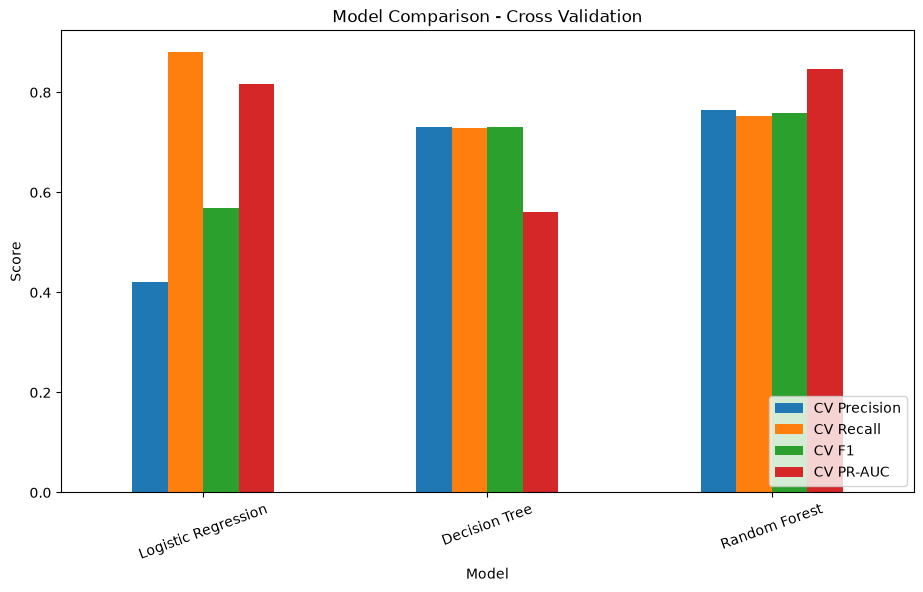

In [1371]:
comparison_plot = comparison_df.set_index("Model")

comparison_plot[
    ["CV Precision", "CV Recall", "CV F1", "CV PR-AUC"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Model Comparison - Cross Validation")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.show()

In [1372]:
best_model_name = (
    comparison_df
    .sort_values(by="CV PR-AUC", ascending=False)
    .iloc[0]["Model"]
)

print("Best Model Based on CV PR-AUC:", best_model_name)

Best Model Based on CV PR-AUC: Random Forest


## hyperparameter Tunning

In [1373]:
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.1, 1, 10]
    },

    "Decision Tree": {
        "classifier__max_depth": [5, 10, 20, None],
        "classifier__min_samples_split": [2, 5, 10],
        "classifier__min_samples_leaf": [1, 2, 5]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [10, 20, None],
        "classifier__min_samples_leaf": [1, 2, 5]
    }
}

In [1374]:
best_model = models[best_model_name]

grid_search = GridSearchCV(
    estimator=best_model,
    param_grid=param_grids[best_model_name],
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(grid_search.best_score_)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}

Best Cross-Validation PR-AUC:
0.8790622905035137


In [1375]:
final_model = grid_search.best_estimator_

print("Final Model Selected:", best_model_name)

Final Model Selected: Random Forest


In [1376]:
# Hyperparameter tuning is used to find the best settings for a machine learning algorithm 
# so that the model can perform better on unseen data.

## Final Model Evaluation

In [1377]:
y_pred = final_model.predict(X_test)

y_prob = final_model.predict_proba(X_test)[:, 1]

In [1378]:
#Calculation avaluation metric
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)

roc_auc = roc_auc_score(y_test, y_prob)

pr_auc = average_precision_score(y_test, y_prob)

print("Final Model Evaluation")

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("ROC-AUC:", roc_auc)
print("PR-AUC (Average Precision):", pr_auc)

Final Model Evaluation
Accuracy: 0.9095
Precision: 0.48260594560404807
Recall: 0.8976470588235295
F1 Score: 0.6277252159605101
ROC-AUC: 0.9756901639344262
PR-AUC (Average Precision): 0.8778857133411753


In [1379]:
#Display the classification report
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Diabetes", "Diabetes"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

 No Diabetes       0.99      0.91      0.95     18300
    Diabetes       0.48      0.90      0.63      1700

    accuracy                           0.91     20000
   macro avg       0.74      0.90      0.79     20000
weighted avg       0.95      0.91      0.92     20000



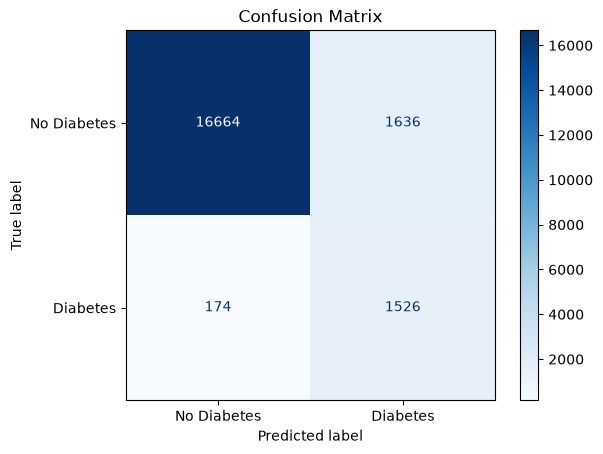

In [1380]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix")
plt.show()

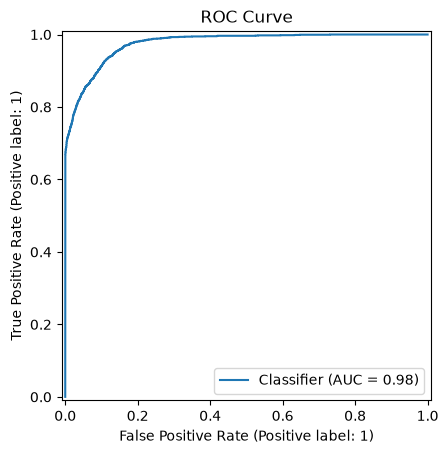

In [1381]:
#Roc curve
RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("ROC Curve")
plt.show()

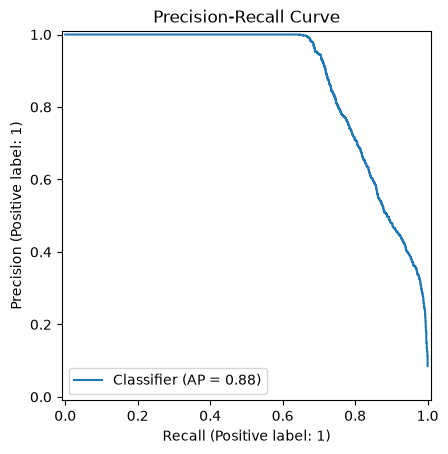

In [1382]:
#precision recall curve
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("Precision-Recall Curve")
plt.show()

In [ ]:
# Understand the confusion matrix:
#     Result	              Meaning
# True Positive-	Correctly predicted diabetes
# True Negative	-Correctly predicted no diabetes
# False Positive-	Predicted diabetes, but actual class is no diabetes
# False Negative-	Predicted no diabetes, but actual class is diabetes

## Feature importance

,Feature,Importance
4,numeric__HbA1c_level,0.408199
5,numeric__blood_glucose_level,0.285400
0,numeric__age,0.156702
3,numeric__bmi,0.071247
1,numeric__hypertension,0.033648
2,numeric__heart_disease,0.017237
9,categorical__smoking_history_No Info,0.016272
12,categorical__smoking_history_former,0.005210
7,categorical__gender_Male,0.001957
6,categorical__gender_Female,0.001752


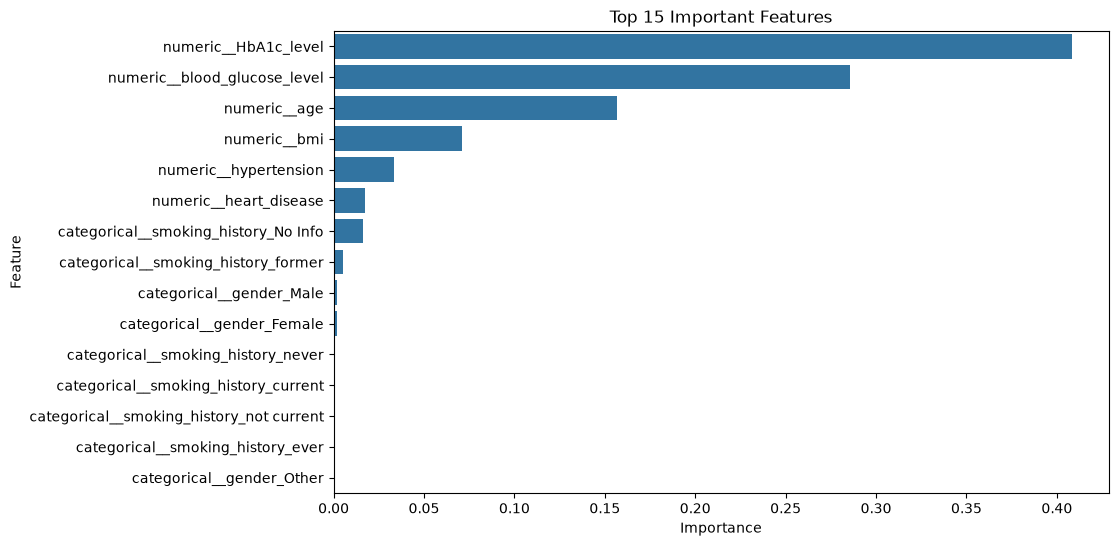

In [1383]:
classifier = final_model.named_steps["classifier"]

if hasattr(classifier, "feature_importances_"):

    feature_names = (
        final_model
        .named_steps["preprocessor"]
        .get_feature_names_out()
    )

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": classifier.feature_importances_
    })

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    )

    display(importance_df)

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=importance_df.head(15),
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Important Features")
    plt.show()

else:
    print("Feature importance is not available for this model.")

In [ ]:
#  Feature importance helps us understand which transformed input features the tree-based model used most.
#  It does not prove that a feature causes diabetes.

#save the model

In [1384]:
joblib.dump(
    final_model,
    "diabetes_prediction_pipeline.pkl"
)

print("Final model saved successfully")

Final model saved successfully


In [1386]:
import json

model_information = {
    "problem_type": "Binary Classification",
    "target_column": "diabetes",
    "selected_model": best_model_name,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "evaluation_metrics": {
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1_score": float(f1),
        "roc_auc": float(roc_auc),
        "pr_auc_average_precision": float(pr_auc)
    }
}

with open("model_information.json", "w") as file:
    json.dump(model_information, file, indent=4)

print("Model information saved successfully")

Model information saved successfully


In [1387]:
#Test loading the model
loaded_model = joblib.load("diabetes_prediction_pipeline.pkl")

print("Saved model loaded successfully")

Saved model loaded successfully


## Test a new prediction

In [ ]:
#This sample is only to demonstrate how to call the model. It is not a real person's diagnosis.

In [1389]:
new_data = pd.DataFrame([{
    "gender": "Female",
    "age": 45,
    "hypertension": 1,
    "heart_disease": 1,
    "smoking_history": "current",
    "bmi": 28.5,
    "HbA1c_level": 5.8,
    "blood_glucose_level": 120
}])

prediction = loaded_model.predict(new_data)

probability = loaded_model.predict_proba(new_data)[0][1]

print("Prediction:", prediction[0])

print("Probability of Class 1:", probability)

if prediction[0] == 1:
    print("Model Prediction: Diabetes")
else:
    print("Model Prediction: No Diabetes")

Prediction: 1
Probability of Class 1: 0.7053581763231059
Model Prediction: Diabetes
